In [1]:
# ============================================================
# HYBRID IDS PIPELINE + SHAP EXPLANATION
# CICIDS2017 → Image → Xception + MobileViT → LightGBM → SHAP
# ============================================================

# ============================================================
# 1. IMPORTS
# ============================================================
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt
import onnxruntime as ort
import cv2
import lime
from PIL import Image
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score

warnings.filterwarnings("ignore")

warnings.filterwarnings("ignore")

DATA_PATH = "train_data.csv"

MOBILEVIT_ONNX_PATH = "mobilevit.onnx"
RESNET_ONNX_PATH = "Resnet.onnx"
RANDOM_FOREST_PATH = "best_random_forest_model.pkl"

IMG_SHAPE = (28, 28)
FEATURE_SIZE = 784

CLASS_NAMES = [
    "BENIGN",
    "DoS",
    "Fuzzy",
    "RPM",
    "Advanced",
    "Patator"
]

# ============================================================
# 3. CHECK FILES
# ============================================================

required_files = [
    DATA_PATH,
    MOBILEVIT_ONNX_PATH,
    RESNET_ONNX_PATH,
    RANDOM_FOREST_PATH
]

for file in required_files:
    if not os.path.exists(file):
        raise FileNotFoundError(f"Missing file: {file}")

print("All required files found.")

# ============================================================
# 4. LOAD DATASET
# ============================================================

print("\nLoading dataset...")

df = pd.read_csv(DATA_PATH, low_memory=False)

df.columns = df.columns.str.strip()

# Remove NaN and infinite values
df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.dropna(inplace=True)

df.reset_index(drop=True, inplace=True)

print(f"Dataset shape: {df.shape}")

# ============================================================
# 5. LABEL MAPPING
# ============================================================

def map_label(label):
    if label == "BENIGN":
        return "BENIGN"
    elif "DoS" in label:
        return "DoS"
    elif "PortScan" in label or "Brute Force" in label:
        return "Fuzzy"
    elif "Web Attack" in label or "Sql Injection" in label or "XSS" in label:
        return "RPM"
    elif "Bot" in label or "Infiltration" in label or "Heartbleed" in label:
        return "Advanced"
    elif "Patator" in label:
        return "Patator"
    else:
        return "Other"

df["Category"] = df["Label"].apply(map_label)

# Remove unwanted class
df = df[df["Category"] != "Other"]

print("\nClass Distribution:")
print(df["Category"].value_counts())

# ============================================================
# 6. FEATURE EXTRACTION
# ============================================================

print("\nPreparing features...")

features = df.select_dtypes(include=[np.number])
labels = df["Category"]

# ============================================================
# 7. FEATURE SCALING & SMART SUBSAMPLING
# ============================================================

scaler = MinMaxScaler()
features_scaled = scaler.fit_transform(features)

# Convert to image pixel range
features_scaled = (features_scaled * 255).astype(np.uint8)

print(f"Total scaled features shape: {features_scaled.shape}")

# --- SMART STRATIFIED SUBSAMPLING TO EXACTLY 3000 SAMPLES ---
TARGET_SAMPLES = 3000
MIN_PER_CLASS = 15  # Enforce a minimum floor so downstream splits have enough samples

print(f"\nSubsampling dataset to {TARGET_SAMPLES} rows (with a floor of {MIN_PER_CLASS} per class)...")

sub_indices = []

# Step 1: Ensure every single class gets its minimum floor first
for category in df["Category"].unique():
    category_indices = df[df["Category"] == category].index.tolist()
    n_take = min(len(category_indices), MIN_PER_CLASS)
    
    # Safely sample the floor for this class
    chosen = pd.Series(category_indices).sample(n=n_take, random_state=42).tolist()
    sub_indices.extend(chosen)

# Step 2: Fill the remaining quota up to 3000 using the rest of the data
remaining_quota = TARGET_SAMPLES - len(sub_indices)

if remaining_quota > 0:
    remaining_indices = df.index.difference(sub_indices)
    remaining_df = df.loc[remaining_indices]
    
    # Exclude any categories that don't have enough remaining rows left to stratify
    rem_counts = remaining_df["Category"].value_counts()
    valid_categories = rem_counts[rem_counts >= 2].index
    strat_df = remaining_df[remaining_df["Category"].isin(valid_categories)]
    
    extra_indices, _ = train_test_split(
        strat_df.index.to_numpy(),
        train_size=remaining_quota,
        stratify=strat_df["Category"],
        random_state=42
    )
    sub_indices.extend(extra_indices)

# Step 3: Slice all your feature arrays and tracking DataFrames synchronously
features_scaled = features_scaled[sub_indices]
features = features.iloc[sub_indices].reset_index(drop=True)
labels = df["Category"].iloc[sub_indices].reset_index(drop=True)

print(f"Final features shape for pipeline: {features_scaled.shape}")
print("\nSubsampled Class Distribution (Safe for Splitting):")
print(labels.value_counts())

# ============================================================
# 8. CREATE IMAGE FUNCTION
# ============================================================

def create_image_from_row(row, size=FEATURE_SIZE):
    data = np.array(row)

    # Padding
    if len(data) < size:
        data = np.pad(
            data,
            (0, size - len(data)),
            mode='constant'
        )
    # Truncate if larger
    else:
        data = data[:size]

    img = data.reshape(IMG_SHAPE)
    return img.astype(np.uint8)

# ============================================================
# 9. IMAGE PREPROCESSING FOR ONNX
# ============================================================

def preprocess_resnet(img):
    # Resize to 224x224
    img = cv2.resize(img, (224, 224))

    # Normalize
    img = img.astype(np.float32) / 255.0

    # Grayscale → RGB (NHWC Format)
    # Note: If your ResNet ONNX model expects NCHW format, change axis=-1 to axis=0
    img = np.stack([img] * 3, axis=-1)

    # Add batch dimension
    img = np.expand_dims(img, axis=0)

    return img.astype(np.float32)

def preprocess_mobilevit(img):
    # Keep 28x28

    # Normalize
    img = img.astype(np.float32) / 255.0

    # Grayscale → 3 channels (NCHW Format)
    img = np.stack([img] * 3, axis=0)

    # Add batch dimension
    img = np.expand_dims(img, axis=0)

    return img.astype(np.float32)

# ============================================================
# 10. SOFTMAX FUNCTION
# ============================================================

def softmax(x):
    exp_x = np.exp(x - np.max(x, axis=1, keepdims=True))
    return exp_x / np.sum(exp_x, axis=1, keepdims=True)

# ============================================================
# 11. LOAD ONNX MODELS
# ============================================================

print("\nLoading ONNX models...")

mobilevit_session = ort.InferenceSession(MOBILEVIT_ONNX_PATH)
resnet_session = ort.InferenceSession(RESNET_ONNX_PATH)

mobilevit_input_name = mobilevit_session.get_inputs()[0].name
resnet_input_name = resnet_session.get_inputs()[0].name

print("ONNX models loaded successfully.")

# ============================================================
# 12. GENERATE META FEATURES
# ============================================================

print("\nGenerating ensemble meta-features...")

meta_features = []
meta_labels = []

for idx in range(len(features_scaled)):
    row = features_scaled[idx]
    label = labels.iloc[idx]

    # Create image
    img = create_image_from_row(row)

    # Preprocess image
    resnet_input = preprocess_resnet(img)
    mobilevit_input = preprocess_mobilevit(img)

    # =========================================
    # RESNET INFERENCE
    # =========================================
    resnet_output = resnet_session.run(
        None,
        {resnet_input_name: resnet_input}
    )[0]
    resnet_probs = softmax(resnet_output)

    # =========================================
    # MOBILEVIT INFERENCE
    # =========================================
    mobilevit_output = mobilevit_session.run(
        None,
        {mobilevit_input_name: mobilevit_input}
    )[0]
    mobilevit_probs = softmax(mobilevit_output)

    # ========================================================
    # CONCATENATE PROBABILITIES & CONFIDENCES (14 FEATURES)
    # ========================================================
    resnet_conf = np.max(resnet_probs[0])
    mobilevit_conf = np.max(mobilevit_probs[0])

    # Flatten everything into a single 1D array of 14 elements
    combined_features = np.concatenate([
        resnet_probs[0],
        mobilevit_probs[0],
        np.array([resnet_conf, mobilevit_conf])
    ])

    meta_features.append(combined_features)
    meta_labels.append(label)

    if idx % 1000 == 0:
        print(f"Processed {idx}/{len(features_scaled)} samples")

# Convert to arrays safely
X_meta = np.array(meta_features)
y_meta = np.array(meta_labels)

print(f"\nMeta feature shape: {X_meta.shape}")

# ============================================================
# 13. LABEL ENCODING
# ============================================================

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y_meta)

print("\nEncoded classes:")
print(label_encoder.classes_)

# ============================================================
# 14. TRAIN / TEST SPLIT (WITH INDEX TRACKING)
# ============================================================

indices = np.arange(len(X_meta))

train_idx, test_idx = train_test_split(
    indices, 
    test_size=0.2, 
    random_state=42, 
    stratify=y_encoded
)

X_train, X_test = X_meta[train_idx], X_meta[test_idx]
y_train, y_test = y_encoded[train_idx], y_encoded[test_idx]

# Keep a reference to the original unscaled test features
X_test_original = features.iloc[test_idx].reset_index(drop=True)

print(f"\nTrain shape: {X_train.shape}")
print(f"Test shape: {X_test.shape}")
print(f"Original Test Features shape: {X_test_original.shape}")

# ============================================================
# 15. TRAIN FRESH RANDOM FOREST META-LEARNER
# ============================================================

from sklearn.ensemble import RandomForestClassifier

print("\nTraining a fresh Random Forest ensemble meta-learner...")
def compute_smoothed_weights(y, smooth_factor=0.15):
    # Count occurrences of each class
    classes, counts = np.unique(y, return_counts=True)
    total_samples = len(y)

    # Apply logarithmic smoothing
    # Ensure counts are not zero to avoid division by zero
    safe_counts = np.where(counts == 0, 1e-6, counts) # Use a small number instead of 0
    smoothed_weights_array = total_samples / (safe_counts ** smooth_factor)

    # Normalize so the minimum weight or average weight stays reasonable
    smoothed_weights_array /= np.mean(smoothed_weights_array)

    # Map class labels to their smoothed weights
    class_weight_dict = {cls: weight for cls, weight in zip(classes, smoothed_weights_array)}
    return class_weight_dict
class_weight_dict_selected = compute_smoothed_weights(y_train, smooth_factor=0.25)
# Initialize the Random Forest with standard, robust hyperparameters
rf_model = RandomForestClassifier(
        random_state=42,
        n_jobs=-1,
        class_weight=class_weight_dict_selected,
        n_estimators=300,
        max_depth=None,
        min_samples_split=4,
        min_samples_leaf=3,
        max_features='log2')

# Train on the 14 meta-features generated from ONNX models
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully.")

# Optional: Save the freshly trained model to disk for future use
fresh_rf_path = "fresh_random_forest_model.pkl"
joblib.dump(rf_model, fresh_rf_path)
print(f"Saved fresh model to: {fresh_rf_path}")

# ============================================================
# 16. EVALUATION (FIXED TO EVALUATE ON TEST SPLIT)
# ============================================================

print("\nEvaluating model on unseen test data...")

# FIX: Predict on X_test instead of X_train to check real performance
y_pred = rf_model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print(f"\nTest Accuracy: {accuracy:.4f}")
print("\nTest Classification Report:\n")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=label_encoder.classes_
    )
)

# ============================================================
# 17. RE-DEFINE FEATURE NAMES & WRAPPER FUNCTION
# ============================================================

feature_names = features.columns.tolist()

def end_to_end_predict_proba(X_tabular_numpy):
    """
    Black-box wrapper that converts raw tabular chunks from LIME 
    back into images, runs ONNX models, and returns Random Forest probabilities.
    """
    # 1. Scale using the already-fitted MinMaxScaler
    X_scaled = scaler.transform(X_tabular_numpy)
    X_scaled = (X_scaled * 255).astype(np.uint8)
    
    meta_features_batch = []
    
    # 2. Process each perturbed row through the DL models
    for i in range(X_scaled.shape[0]):
        # Force extract a clean 1D array for the current sample
        row = X_scaled[i, :].flatten()
        
        # Create the 28x28 image safely
        img = create_image_from_row(row)
        
        # Preprocess for ONNX format requirements
        resnet_input = preprocess_resnet(img)
        mobilevit_input = preprocess_mobilevit(img)
        
        # Run deep learning inference
        res_out = resnet_session.run(None, {resnet_input_name: resnet_input})[0]
        res_probs = softmax(res_out)[0]
        
        mv_out = mobilevit_session.run(None, {mobilevit_input_name: mobilevit_input})[0]
        mv_probs = softmax(mv_out)[0]
        
        # Calculate confidences
        res_conf = np.max(res_probs)
        mv_conf = np.max(mv_probs)
        
        # Reconstruct the 14 meta-features exactly how the RF expects them
        combined_features = np.concatenate([
            res_probs, 
            mv_probs, 
            np.array([res_conf, mv_conf])
        ])
        
        meta_features_batch.append(combined_features)
        
    # 3. Feed the generated meta-features into the Random Forest
    return rf_model.predict_proba(np.array(meta_features_batch))
# ============================================================
# 18. INITIALIZE LIME TABULAR EXPLAINER
# ============================================================

print("\nInitializing LIME Explainer...")

# Reconstruct the original unscaled training data to feed to LIME
X_train_original = features.iloc[train_idx].values

# FIX: Replaced undefined class_names_encoded with label_encoder.classes_
explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train_original,
    feature_names=feature_names,
    class_names=list(label_encoder.classes_),
    mode='classification',
    random_state=42
)

print("LIME Explainer ready.")

# ============================================================
# 19. EXPLAIN A SINGLE INSTANCE WITH LIME
# ============================================================

print("\nGenerating LIME explanation for a single sample...")

sample_index = 0

# Grab the raw tabular row we want to explain
test_instance = X_test_original.iloc[sample_index].values
actual_label = label_encoder.inverse_transform([y_test[sample_index]])[0]

# Generate the explanation
lime_exp = explainer.explain_instance(
    data_row=test_instance,
    predict_fn=end_to_end_predict_proba,
    num_features=10,
    top_labels=1 # Only explain the most likely predicted class
)

# Output prediction text to console
predicted_class_idx = lime_exp.available_labels()[0]
# FIX: Replaced undefined class_names_encoded here too
predicted_class_name = label_encoder.classes_[predicted_class_idx]
print(f"Actual Class: {actual_label}")
print(f"Predicted Class: {predicted_class_name}")

/home/minyar/onnx_xai_env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


All required files found.

Loading dataset...
Dataset shape: (1696725, 79)

Class Distribution:
Category
BENIGN      1362791
DoS          227842
Fuzzy         96186
Patator        8299
Advanced       1203
RPM             404
Name: count, dtype: int64

Preparing features...
Total scaled features shape: (1696725, 78)

Subsampling dataset to 3000 rows (with a floor of 15 per class)...
Final features shape for pipeline: (3000, 78)

Subsampled Class Distribution (Safe for Splitting):
Category
BENIGN      2352
DoS          406
Fuzzy        180
Patator       29
Advanced      17
RPM           16
Name: count, dtype: int64

Loading ONNX models...
ONNX models loaded successfully.

Generating ensemble meta-features...
Processed 0/3000 samples
Processed 1000/3000 samples
Processed 2000/3000 samples

Meta feature shape: (3000, 14)

Encoded classes:
['Advanced' 'BENIGN' 'DoS' 'Fuzzy' 'Patator' 'RPM']

Train shape: (2400, 14)
Test shape: (600, 14)
Original Test Features shape: (600, 78)

Training a fr


Generating LIME explanation for a single sample...
Actual Class: Fuzzy
Predicted Class: Fuzzy
Saved interactive LIME dashboard to: lime_explanation_Fuzzy.html


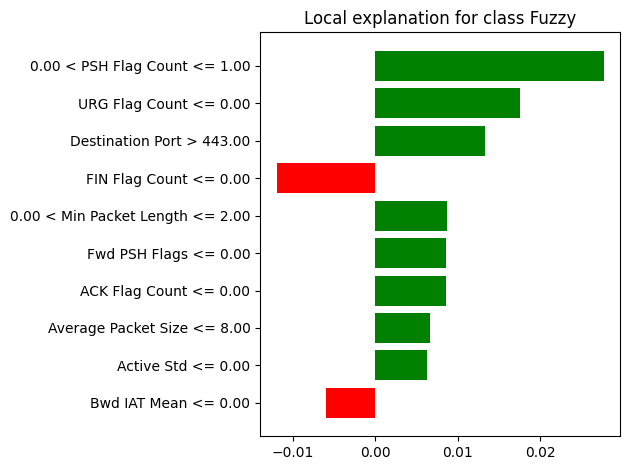

Saved static LIME plot to: lime_bar_plot.png


In [3]:
print("\nGenerating LIME explanation for a single sample...")
# ============================================================
# 17. RE-DEFINE FEATURE NAMES & FIXED WRAPPER FUNCTION
# ============================================================

feature_names = features.columns.tolist()


sample_index = 8

# Grab the raw tabular row we want to explain
test_instance = X_test_original.iloc[sample_index].values
actual_label = label_encoder.inverse_transform([y_test[sample_index]])[0]

# Generate the explanation
lime_exp = explainer.explain_instance(
    data_row=test_instance,
    predict_fn=end_to_end_predict_proba,
    num_features=10,
    top_labels=1 # Only explain the most likely predicted class
)

# Output prediction text to console
predicted_class_idx = lime_exp.available_labels()[0]
# FIX: Replaced undefined class_names_encoded here too
predicted_class_name = label_encoder.classes_[predicted_class_idx]
print(f"Actual Class: {actual_label}")
print(f"Predicted Class: {predicted_class_name}")
# ============================================================
# 20. SAVE LIME VISUALIZATIONS
# ============================================================

# 1. Save as an interactive HTML file (Best for viewing in a browser)
html_path = f"lime_explanation_{actual_label}.html"
lime_exp.save_to_file(html_path)
print(f"Saved interactive LIME dashboard to: {html_path}")

# 2. Save as a static Matplotlib figure
fig = lime_exp.as_pyplot_figure(label=predicted_class_idx)
plt.tight_layout()
plt.savefig(f"lime_bar_plot_{actual_label}.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved static LIME plot to: lime_bar_plot.png")


In [6]:
import numpy as np

print("\nFinding sample indices for each class in the test set...")

class_sample_indices = {}

# Loop through all the encoded classes (0, 1, 2, 3...)
for encoded_class_value, class_name in enumerate(label_encoder.classes_):
    
    # Find all indices in y_test that match this specific class
    matching_indices = np.where(y_test == encoded_class_value)[0]
    
    if len(matching_indices) > 0:
        # Grab the very first index from the matches
        first_idx = matching_indices
        class_sample_indices[class_name] = first_idx
        print(f"{class_name} (Class {encoded_class_value}) -> Index {first_idx}")
    else:
        print(f"{class_name} -> No samples found in test set.")


Finding sample indices for each class in the test set...
Advanced (Class 0) -> Index [ 13  59 104 437]
BENIGN (Class 1) -> Index [  0   1   3   4   5   6   7   9  10  11  12  14  15  19  20  22  23  24
  26  28  29  30  31  32  33  34  36  37  39  40  41  44  45  47  48  50
  53  54  55  57  58  60  61  62  63  67  69  70  71  72  73  74  75  76
  77  78  79  81  83  84  85  87  89  92  94  95  96  97  98  99 100 102
 103 105 106 107 108 111 112 113 114 115 116 117 119 121 122 123 124 125
 127 130 131 132 133 134 137 138 139 140 141 145 146 147 148 149 150 151
 152 153 154 155 156 157 160 161 162 163 165 166 167 169 170 172 173 174
 175 176 177 178 179 180 181 182 183 185 186 187 188 189 190 191 192 194
 195 196 197 198 202 204 205 206 207 208 209 210 211 212 213 214 216 219
 220 221 223 225 226 227 228 229 230 231 232 233 234 235 236 239 240 241
 242 243 244 245 246 247 248 250 251 252 253 254 255 256 257 258 259 260
 261 262 263 264 265 266 267 268 270 271 272 275 278 280 281 283 28

In [4]:
from sklearn.metrics import auc

# ============================================================
# 21. EVALUATE LIME: SPARSITY & COMPLETENESS
# ============================================================

print("\nCalculating LIME Evaluation Metrics...")

# ------------------------------------------------------------
# A. Generate a "Full" Explanation for Metrics
# ------------------------------------------------------------
# To measure sparsity and completeness accurately across the whole 
# feature space, we need LIME to weight ALL features, not just 10.
lime_exp_full = explainer.explain_instance(
    data_row=test_instance,
    predict_fn=end_to_end_predict_proba,
    num_features=len(feature_names), # Request all 784 features
    top_labels=1
)

predicted_class_idx = lime_exp_full.available_labels()[0]

# ------------------------------------------------------------
# B. Convert LIME output to a dense 1D array
# ------------------------------------------------------------
lime_weights = np.zeros(len(feature_names))

# LIME local_exp returns a list of tuples: (feature_idx, weight)
for feat_idx, weight in lime_exp_full.local_exp[predicted_class_idx]:
    lime_weights[feat_idx] = weight

# ------------------------------------------------------------
# C. Calculate Sparsity (AUC of Cumulative Importance)
# ------------------------------------------------------------
def calculate_sparsity_auc(weights):
    # Sort absolute weights in descending order
    sorted_abs_weights = np.sort(np.abs(weights))[::-1]
    
    # Calculate cumulative sum
    cumulative_importance = np.cumsum(sorted_abs_weights)
    
    # Normalize to 0-1 range
    if cumulative_importance[-1] > 0:
        cumulative_importance = cumulative_importance / cumulative_importance[-1]
    else:
        return 0.0, cumulative_importance
        
    # Calculate Area Under the Curve
    x_axis = np.linspace(0, 1, len(cumulative_importance))
    return auc(x_axis, cumulative_importance), cumulative_importance

sparsity_score, cum_curve = calculate_sparsity_auc(lime_weights)
print(f"LIME Sparsity AUC: {sparsity_score:.4f}")

# ------------------------------------------------------------
# D. Calculate Completeness (Probability Retention)
# ------------------------------------------------------------
def calculate_completeness(sample, weights, predict_fn, baseline, class_index, top_k=20):
    # 1. Get original prediction probability
    orig_pred = predict_fn(sample.reshape(1, -1))[0, class_index]
    
    # 2. Get indices of top K features from LIME weights
    top_k_indices = np.argsort(np.abs(weights))[-top_k:]
    
    # 3. Mask the sample (Baseline everywhere, except top K features)
    masked_sample = np.copy(baseline)
    masked_sample[top_k_indices] = sample[top_k_indices]
    
    # 4. Get new prediction probability using the masked sample
    masked_pred = predict_fn(masked_sample.reshape(1, -1))[0, class_index]
    
    # 5. Calculate retention
    retention = masked_pred / orig_pred if orig_pred > 0 else 0.0
    return retention

# The LIME baseline is typically the mean of the training data
bg_mean = X_train_original.mean(axis=0)

completeness_score = calculate_completeness(
    sample=test_instance,
    weights=lime_weights,
    predict_fn=end_to_end_predict_proba,
    baseline=bg_mean,
    class_index=predicted_class_idx,
    top_k=20
)

print(f"LIME Completeness (Top-20 Retention): {completeness_score:.4f}")


Calculating LIME Evaluation Metrics...
LIME Sparsity AUC: 0.8291
LIME Completeness (Top-20 Retention): 0.7607


In [5]:
# ============================================================
# 22. LIME LOCAL FIDELITY (R^2)
# ============================================================

print("\nExtracting LIME Local Fidelity...")

sample_idx = 1
sample_to_test = X_test_original.iloc[sample_idx].values

# 1. Generate the explanation
lime_exp = explainer.explain_instance(
    data_row=sample_to_test,
    predict_fn=end_to_end_predict_proba,
    num_features=len(feature_names),
    top_labels=1
)

# 2. Extract the built-in R^2 score safely
if isinstance(lime_exp.score, (int, float)):
    # If it's a direct float, use it as-is
    fidelity_score = lime_exp.score
else:
    # Fallback if your environment returns a dictionary/list
    predicted_class_idx = lime_exp.available_labels()[0]
    fidelity_score = lime_exp.score[predicted_class_idx]

print(f"LIME Local Fidelity (R^2): {fidelity_score:.4f}")


Extracting LIME Local Fidelity...
LIME Local Fidelity (R^2): 0.0822


In [6]:
import time

# ============================================================
# 23. LIME EFFICIENCY (COMPUTATIONAL TIME)
# ============================================================
print("\nMeasuring LIME Computational Efficiency...")

start_time = time.time()

# Run a fresh explanation to isolate execution time
_ = explainer.explain_instance(
    data_row=test_instance,
    predict_fn=end_to_end_predict_proba,
    num_features=len(feature_names),
    top_labels=1
)

efficiency_score = time.time() - start_time
print(f"LIME Efficiency: {efficiency_score:.4f} seconds per sample")


# ============================================================
# 24. LIME STABILITY (SAMPLING CONSISTENCY)
# ============================================================
print("\nCalculating LIME Internal Stability...")

# Generate two separate explanations for the EXACT SAME sample.
# Because LIME uses stochastic (random) sampling, this measures variance.
exp_run1 = explainer.explain_instance(
    data_row=test_instance,
    predict_fn=end_to_end_predict_proba,
    num_features=len(feature_names),
    top_labels=1
)

exp_run2 = explainer.explain_instance(
    data_row=test_instance,
    predict_fn=end_to_end_predict_proba,
    num_features=len(feature_names),
    top_labels=1
)

# Extract dense weights for both runs
w_run1 = np.zeros(len(feature_names))
w_run2 = np.zeros(len(feature_names))

c_run1 = exp_run1.available_labels()[0]
c_run2 = exp_run2.available_labels()[0]

for feat_idx, weight in exp_run1.local_exp[c_run1]: w_run1[feat_idx] = weight
for feat_idx, weight in exp_run2.local_exp[c_run2]: w_run2[feat_idx] = weight

# Calculate Stability via Cosine Similarity between the two weight profiles
denominator = (np.linalg.norm(w_run1) * np.linalg.norm(w_run2))
stability_score = np.dot(w_run1, w_run2) / denominator if denominator > 0 else 0.0

print(f"LIME Stability (Identical Input Cosine Similarity): {stability_score:.4f}")


# ============================================================
# 25. LIME ROBUSTNESS (INPUT NOISE SENSITIVITY)
# ============================================================
print("\nCalculating LIME Robustness against Feature Noise...")

# 1. Create a perturbed instance by adding tiny Gaussian noise (1% of feature standard deviation)
feature_stds = X_train_original.std(axis=0)
noise = np.random.normal(0, 0.01 * (feature_stds + 1e-9), size=test_instance.shape)

# Ensure the noisy sample stays within valid training boundaries
min_bounds = X_train_original.min(axis=0)
max_bounds = X_train_original.max(axis=0)
perturbed_instance = np.clip(test_instance + noise, min_bounds, max_bounds)

# 2. Explain the perturbed instance
exp_perturbed = explainer.explain_instance(
    data_row=perturbed_instance,
    predict_fn=end_to_end_predict_proba,
    num_features=len(feature_names),
    top_labels=1
)

w_perturbed = np.zeros(len(feature_names))
c_perturbed = exp_perturbed.available_labels()[0]

for feat_idx, weight in exp_perturbed.local_exp[c_perturbed]: 
    w_perturbed[feat_idx] = weight

# 3. Calculate Robustness via Cosine Similarity between Original and Noisy explanations
denom_robust = (np.linalg.norm(w_run1) * np.linalg.norm(w_perturbed))
robustness_score = np.dot(w_run1, w_perturbed) / denom_robust if denom_robust > 0 else 0.0

print(f"LIME Robustness (Noisy Input Cosine Similarity): {robustness_score:.4f}")


Measuring LIME Computational Efficiency...
LIME Efficiency: 183.0337 seconds per sample

Calculating LIME Internal Stability...
LIME Stability (Identical Input Cosine Similarity): 0.8568

Calculating LIME Robustness against Feature Noise...
LIME Robustness (Noisy Input Cosine Similarity): 0.5146
